# Tools

In [1]:
import os 
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["GROQ_API_KEYG"] = os.getenv("GROQ_API_KEY")

In [4]:
from langchain.tools import tool
from langchain.chat_models import init_chat_model



llm = init_chat_model("groq:openai/gpt-oss-120b")

@tool
def weather(location: str)-> str:
    """ 
    Get the weather at a specified location
    """

    return f"Its sunny in {location}"

model_with_tool = llm.bind_tools([weather])

In [5]:
model_with_tool.invoke("What is weather in Bengaluru")

AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "What is weather in Bengaluru". Need to fetch weather via function. Use functions.weather with location "Bengaluru".', 'tool_calls': [{'id': 'fc_52b24d11-e066-4932-89cc-edfda10689e2', 'function': {'arguments': '{"location":"Bengaluru"}', 'name': 'weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 58, 'prompt_tokens': 125, 'total_tokens': 183, 'completion_time': 0.122181558, 'completion_tokens_details': {'reasoning_tokens': 29}, 'prompt_time': 0.00665928, 'prompt_tokens_details': None, 'queue_time': 0.320503969, 'total_time': 0.128840838}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_dee443f41b', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cb2e-2b47-7f13-8ed0-e9b3dafda72d-0', tool_calls=[{'name': 'weather', 'args': {'location': 'Bengaluru'}, 'id': 'fc_52b24d11-e066-4932-89cc-edfda10

# **MiddleWares**


In [6]:
import langchain
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage,SystemMessage
from langchain.chat_models import init_chat_model

llm = init_chat_model("groq:openai/gpt-oss-120b")

agent = create_agent(
    model = llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model = llm,
            trigger=("messages",10),
            keep = ("messages",4),
        )
    ]
)



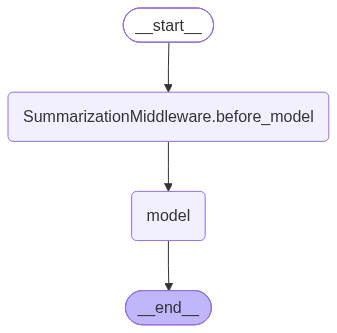

In [7]:
agent

In [ ]:
config = {"configurable":{"thread_id":"test-1"}}


questions = [
    "what is 2+2",
    "what is 100*6",
    "what is 20000/4",
    "what is 17-18",
    "what is 5*4",
    "what is 6*6"
]
for q in questions:
    response = agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")



In [11]:

for q in questions:
    response = agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")

Messages: {'messages': [HumanMessage(content='what is 2+2', additional_kwargs={}, response_metadata={}, id='4be681be-3c07-44fc-93db-af39e165c9c7'), AIMessage(content='2\u202f+\u202f2\u202f=\u202f4.', additional_kwargs={'reasoning_content': 'User asks "what is 2+2". Simple. Answer: 4.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 77, 'total_tokens': 114, 'completion_time': 0.077948882, 'completion_tokens_details': {'reasoning_tokens': 18}, 'prompt_time': 0.003435085, 'prompt_tokens_details': None, 'queue_time': 0.367771752, 'total_time': 0.081383967}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_90620edd96', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cb41-a47a-77e3-a57e-14dc680dc0b8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 77, 'output_tokens': 37, 'total_tokens': 114, 'output_token_details': {'reasoning': 18}})]}
Messages: 2
Message

In [31]:
@tool
def weather(location:str) -> str:
    """ 
    Get the weather from user specified location
    """

    return f"its sunny in {location}"


In [16]:
from langchain.agents import create_agent
agent = create_agent(
    model = llm,
    tools = [weather],
    system_prompt="you are helpfull assitant"
)

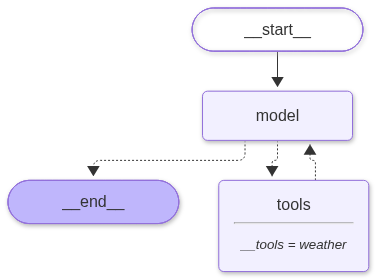

In [17]:
agent

In [33]:
response= agent.invoke(
    {
        "messages":[
            {
                "role":"user",
                "content":"what is the weather in chenni"
            }
        ]
    }
)

In [34]:
response

{'messages': [HumanMessage(content='what is the weather in chenni', additional_kwargs={}, response_metadata={}, id='792b28ff-1959-4a3d-90f6-8bc09f606740'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'vprdy452y', 'function': {'arguments': '{"location":"Chennai"}', 'name': 'weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 284, 'total_tokens': 311, 'completion_time': 0.07787364, 'completion_tokens_details': None, 'prompt_time': 0.019920172, 'prompt_tokens_details': None, 'queue_time': 0.051030847, 'total_time': 0.097793812}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cb66-d7b7-7c50-958c-29f3a533c3b6-0', tool_calls=[{'name': 'weather', 'args': {'location': 'Chennai'}, 'id': 'vprdy452y', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_toke

In [35]:
response["messages"][-1].content

"It's currently **sunny** in Chennai. 🌞"

In [23]:
response= agent.invoke(
    {
        "messages":[
            {
                "role":"user",
                "content":"what is capital of india"
            }
        ]
    }
)

In [24]:
response["messages"][-1].content

'The capital of India is **New\u202fDelhi**.'

In [25]:
llm.invoke("what is the weather in bengaluru").content

'I’m not able to pull live weather data, so I can’t give you the exact temperature, humidity, or forecast for Bengaluru right this moment.  \n\n**What you can do to get the current conditions:**\n\n| Service | How to check |\n|---------|--------------|\n| **Weather.com** | Search “Bengaluru weather” on the site or use the mobile app. |\n| **Google** | Type “Bengaluru weather” into the search bar; the card at the top shows temperature, chance of rain, wind, etc. |\n| **AccuWeather** | Look up “Bengaluru, Karnataka, India” for hourly and 15‑day forecasts. |\n| **Local news apps** | Many Indian news portals (e.g., The Hindu, Deccan Chronicle) embed up‑to‑date weather widgets. |\n| **Voice assistants** | Ask Siri, Google Assistant, or Alexa “What’s the weather in Bengaluru?” |\n\n---\n\n### Typical Climate in Bengaluru (for context)\n\n| Season | Approx. Months | Typical Weather |\n|--------|----------------|-----------------|\n| **Winter (dry season)** | Dec\u202f–\u202fFeb | Mild days (2

In [ ]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import HumanMessage,SystemMessage
from langchain.chat_models import init_chat_model

llm = init_chat_model("groq:qwen/qwen3.8-27b")

agent = create_agent(
    model = llm,
    tools = [weather],
    system_prompt="you are helpfull assitant"
)


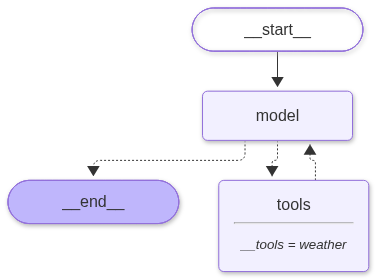

In [27]:
agent

In [28]:
response= agent.invoke(
    {
        "messages":[
            {
                "role":"user",
                "content":"what is the weather in bengaluru"
            }
        ]
    }
)

In [29]:
response["messages"][-1].content

"It's currently sunny in Bengaluru! ☀️\n\nLet me know if you'd like more details or have any other questions."

In [32]:
config = {"configurable":{"thread_id":"test-1"}}


questions = [
    "what is 2+2",
    "what is 100*6",
    "what is 20000/4",
    "what is 17-18",
    "what is 5*4",
    "what is 6*6"
]
for q in questions:
    response = agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")



Messages: {'messages': [HumanMessage(content='what is 2+2', additional_kwargs={}, response_metadata={}, id='7b4ce8cd-32ef-453b-9443-26564e4be637'), AIMessage(content='2 + 2 = 4', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 283, 'total_tokens': 291, 'completion_time': 0.015624395, 'completion_tokens_details': None, 'prompt_time': 0.020002061, 'prompt_tokens_details': None, 'queue_time': 0.57805972, 'total_time': 0.035626456}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_21e59ac2de', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cb55-2d95-7d00-a423-d51b9ed43a5c-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 283, 'output_tokens': 8, 'total_tokens': 291})]}
Messages: 2
Messages: {'messages': [HumanMessage(content='what is 100*6', additional_kwargs={}, response_metadata={}, id='f5d696ee-a04c-4acb-8657-024260f8fa24'), AIMessage(c

In [41]:
from click import prompt
from langchain_groq import ChatGroq

model = ChatGroq(
    model = "qwen/qwen3.8-27b",
    max_tokens=200
)

In [43]:
model.invoke("can you write song in 400 lines").response_metadata

{'token_usage': {'completion_tokens': 200,
  'prompt_tokens': 22,
  'total_tokens': 222,
  'completion_time': 0.380539378,
  'completion_tokens_details': None,
  'prompt_time': 0.001286551,
  'prompt_tokens_details': None,
  'queue_time': 0.048372148,
  'total_time': 0.381825929},
 'model_name': 'qwen/qwen3.8-27b',
 'system_fingerprint': 'fp_21e59ac2de',
 'service_tier': 'on_demand',
 'finish_reason': 'length',
 'logprobs': None,
 'model_provider': 'groq'}

In [44]:
from langchain.agents import create_agent
from torch import mode

agent = create_agent(model=model,tools=[])

config = {"configurable":{"thread_id":"test-1"}}


questions = [
    "what is 2+2",
    "what is 100*6",
    "what is 20000/4",
    "what is 17-18",
    "what is 5*4",
    "what is 6*6"
]
for q in questions:
    response = agent.invoke({"messages":[HumanMessage(content=q)]},config)
    print(f"Messages: {response}")
    print(f"Messages: {len(response['messages'])}")



Messages: {'messages': [HumanMessage(content='what is 2+2', additional_kwargs={}, response_metadata={}, id='9472c42f-d323-4d50-bb07-1501e82f17a0'), AIMessage(content='2 + 2 = **4**', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 18, 'total_tokens': 27, 'completion_time': 0.01731043, 'completion_tokens_details': None, 'prompt_time': 0.000946885, 'prompt_tokens_details': None, 'queue_time': 0.048090784, 'total_time': 0.018257315}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1cb6d-af02-70f0-aba7-56a0f5efbd7e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 18, 'output_tokens': 9, 'total_tokens': 27})]}
Messages: 2
Messages: {'messages': [HumanMessage(content='what is 100*6', additional_kwargs={}, response_metadata={}, id='ec0d11fa-57cf-4066-8ccc-a977a0d00709'), AIMessage(c